<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HancockROC%2BPRCurves.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Checking coordinate counts...
ANN: 29 ROC points, 66 PR points — verified
CNN: 32 ROC points, 66 PR points — verified
GPT2Tab: 31 ROC points, 66 PR points — verified
GPT2L4B: 33 ROC points, 66 PR points — verified

ROC-AUC calculated from supplied coordinates:
ANN: 0.828755
CNN: 0.815934
GPT2Tab: 0.811355
GPT2L4B: 0.777472


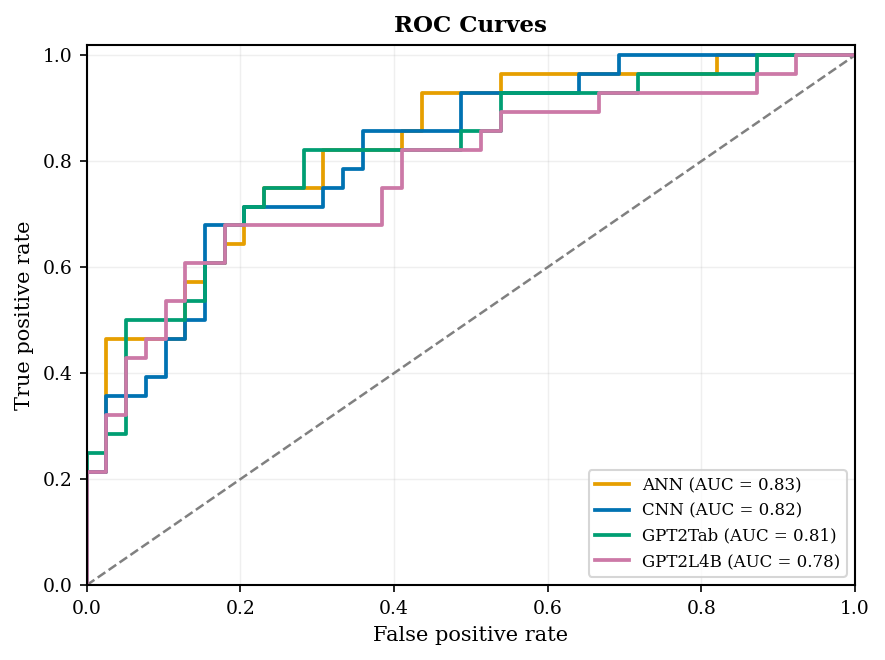

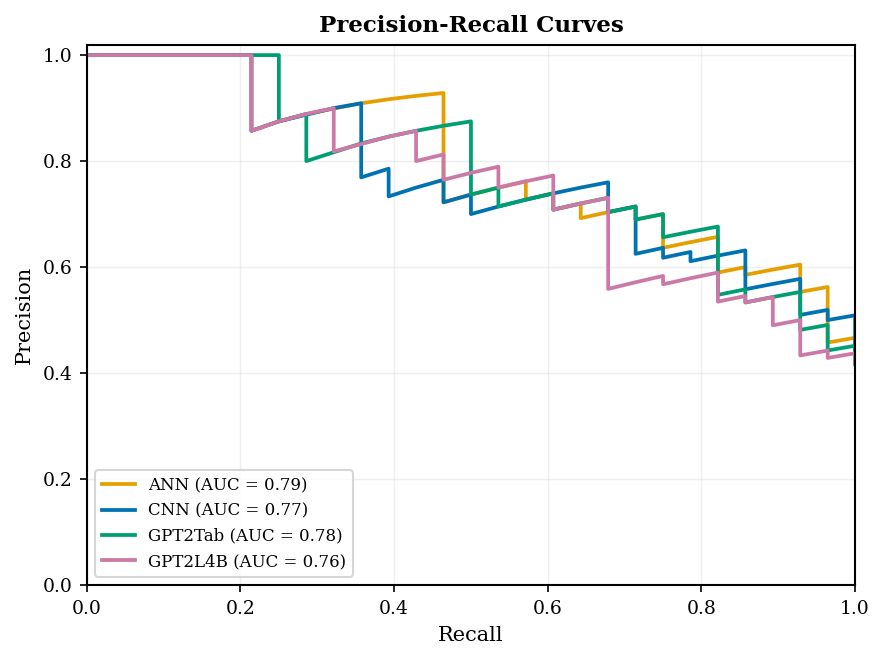

In [7]:
import os
import shutil
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import auc
from google.colab import files

# ============================================================
# ORIGINAL COORDINATES
# ROC format: (FPR, TPR)
# PR format:  (Recall, Precision)
# Thresholds are not needed to plot the curves.
# ============================================================

curves = {
    "ANN": {
        "roc": [
            (0.000000, 0.000000), (0.000000, 0.035714), (0.000000, 0.214286),
            (0.025641, 0.214286), (0.025641, 0.285714), (0.025641, 0.357143),
            (0.025641, 0.464286), (0.128205, 0.464286), (0.128205, 0.571429),
            (0.153846, 0.571429), (0.153846, 0.607143), (0.179487, 0.607143),
            (0.179487, 0.642857), (0.205128, 0.642857), (0.205128, 0.714286),
            (0.230769, 0.714286), (0.230769, 0.750000), (0.307692, 0.750000),
            (0.307692, 0.821429), (0.410256, 0.821429), (0.410256, 0.857143),
            (0.435897, 0.857143), (0.435897, 0.928571), (0.538462, 0.928571),
            (0.538462, 0.964286), (0.820513, 0.964286), (0.820513, 1.000000),
            (0.871795, 1.000000), (1.000000, 1.000000),
        ],
        "pr": [
            (1.000000, 0.417910), (1.000000, 0.424242), (1.000000, 0.430769),
            (1.000000, 0.437500), (1.000000, 0.444444), (1.000000, 0.451613),
            (1.000000, 0.466667), (0.964286, 0.457627), (0.964286, 0.465517),
            (0.964286, 0.473684), (0.964286, 0.482143), (0.964286, 0.490909),
            (0.964286, 0.500000), (0.964286, 0.509434), (0.964286, 0.519231),
            (0.964286, 0.529412), (0.964286, 0.540000), (0.964286, 0.551020),
            (0.964286, 0.562500), (0.928571, 0.553191), (0.928571, 0.565217),
            (0.928571, 0.577778), (0.928571, 0.590909), (0.928571, 0.604651),
            (0.892857, 0.595238), (0.857143, 0.585366), (0.857143, 0.600000),
            (0.821429, 0.589744), (0.821429, 0.605263), (0.821429, 0.621622),
            (0.821429, 0.638889), (0.821429, 0.657143), (0.785714, 0.647059),
            (0.750000, 0.636364), (0.750000, 0.656250), (0.750000, 0.677419),
            (0.750000, 0.700000), (0.714286, 0.689655), (0.714286, 0.714286),
            (0.678571, 0.703704), (0.642857, 0.692308), (0.642857, 0.720000),
            (0.607143, 0.708333), (0.607143, 0.739130), (0.571429, 0.727273),
            (0.571429, 0.761905), (0.535714, 0.750000), (0.500000, 0.736842),
            (0.464286, 0.722222), (0.464286, 0.764706), (0.464286, 0.812500),
            (0.464286, 0.866667), (0.464286, 0.928571), (0.428571, 0.923077),
            (0.392857, 0.916667), (0.357143, 0.909091), (0.285714, 0.888889),
            (0.250000, 0.875000), (0.214286, 0.857143), (0.214286, 1.000000),
            (0.178571, 1.000000), (0.142857, 1.000000), (0.107143, 1.000000),
            (0.071429, 1.000000), (0.035714, 1.000000), (0.000000, 1.000000),
        ],
    },

    "CNN": {
        "roc": [
            (0.000000, 0.000000), (0.000000, 0.035714), (0.000000, 0.214286),
            (0.025641, 0.214286), (0.025641, 0.250000), (0.025641, 0.321429),
            (0.025641, 0.357143), (0.076923, 0.357143), (0.076923, 0.392857),
            (0.102564, 0.392857), (0.102564, 0.464286), (0.128205, 0.464286),
            (0.128205, 0.500000), (0.153846, 0.500000), (0.153846, 0.678571),
            (0.205128, 0.678571), (0.205128, 0.714286), (0.307692, 0.714286),
            (0.307692, 0.750000), (0.333333, 0.750000), (0.333333, 0.785714),
            (0.358974, 0.785714), (0.358974, 0.857143), (0.487179, 0.857143),
            (0.487179, 0.928571), (0.641026, 0.928571), (0.641026, 0.964286),
            (0.692308, 0.964286), (0.692308, 1.000000), (0.820513, 1.000000),
            (0.871795, 1.000000), (1.000000, 1.000000),
        ],
        "pr": [
            (1.000000, 0.417910), (1.000000, 0.424242), (1.000000, 0.430769),
            (1.000000, 0.437500), (1.000000, 0.444444), (1.000000, 0.451613),
            (1.000000, 0.466667), (1.000000, 0.474576), (1.000000, 0.482759),
            (1.000000, 0.491228), (1.000000, 0.500000), (1.000000, 0.509091),
            (0.964286, 0.500000), (0.964286, 0.509434), (0.964286, 0.519231),
            (0.928571, 0.509804), (0.928571, 0.520000), (0.928571, 0.530612),
            (0.928571, 0.541667), (0.928571, 0.553191), (0.928571, 0.565217),
            (0.928571, 0.577778), (0.892857, 0.568182), (0.857143, 0.558140),
            (0.857143, 0.571429), (0.857143, 0.585366), (0.857143, 0.600000),
            (0.857143, 0.615385), (0.857143, 0.631579), (0.821429, 0.621622),
            (0.785714, 0.611111), (0.785714, 0.628571), (0.750000, 0.617647),
            (0.750000, 0.636364), (0.714286, 0.625000), (0.714286, 0.645161),
            (0.714286, 0.666667), (0.714286, 0.689655), (0.714286, 0.714286),
            (0.678571, 0.703704), (0.678571, 0.730769), (0.678571, 0.760000),
            (0.642857, 0.750000), (0.607143, 0.739130), (0.571429, 0.727273),
            (0.535714, 0.714286), (0.500000, 0.700000), (0.500000, 0.736842),
            (0.464286, 0.722222), (0.464286, 0.764706), (0.428571, 0.750000),
            (0.392857, 0.733333), (0.392857, 0.785714), (0.357143, 0.769231),
            (0.357143, 0.833333), (0.357143, 0.909091), (0.321429, 0.900000),
            (0.250000, 0.875000), (0.214286, 0.857143), (0.214286, 1.000000),
            (0.178571, 1.000000), (0.142857, 1.000000), (0.107143, 1.000000),
            (0.071429, 1.000000), (0.035714, 1.000000), (0.000000, 1.000000),
        ],
    },

    "GPT2Tab": {
        "roc": [
            (0.000000, 0.000000), (0.000000, 0.035714), (0.000000, 0.250000),
            (0.025641, 0.250000), (0.025641, 0.285714), (0.051282, 0.285714),
            (0.051282, 0.357143), (0.051282, 0.500000), (0.128205, 0.500000),
            (0.128205, 0.535714), (0.153846, 0.535714), (0.153846, 0.607143),
            (0.179487, 0.607143), (0.179487, 0.678571), (0.205128, 0.678571),
            (0.205128, 0.714286), (0.230769, 0.714286), (0.230769, 0.750000),
            (0.282051, 0.750000), (0.282051, 0.821429), (0.487179, 0.821429),
            (0.487179, 0.857143), (0.538462, 0.857143), (0.538462, 0.928571),
            (0.717949, 0.928571), (0.717949, 0.964286), (0.769231, 0.964286),
            (0.820513, 0.964286), (0.871795, 0.964286), (0.871795, 1.000000),
            (1.000000, 1.000000),
        ],
        "pr": [
            (1.000000, 0.417910), (1.000000, 0.424242), (1.000000, 0.430769),
            (1.000000, 0.437500), (1.000000, 0.444444), (1.000000, 0.451613),
            (0.964286, 0.442623), (0.964286, 0.450000), (0.964286, 0.457627),
            (0.964286, 0.473684), (0.964286, 0.482143), (0.964286, 0.490909),
            (0.928571, 0.481481), (0.928571, 0.490566), (0.928571, 0.500000),
            (0.928571, 0.509804), (0.928571, 0.520000), (0.928571, 0.530612),
            (0.928571, 0.541667), (0.928571, 0.553191), (0.892857, 0.543478),
            (0.857143, 0.533333), (0.857143, 0.545455), (0.857143, 0.558140),
            (0.821429, 0.547619), (0.821429, 0.560976), (0.821429, 0.575000),
            (0.821429, 0.589744), (0.821429, 0.605263), (0.821429, 0.621622),
            (0.821429, 0.638889), (0.821429, 0.657143), (0.821429, 0.676471),
            (0.785714, 0.666667), (0.750000, 0.656250), (0.750000, 0.677419),
            (0.750000, 0.700000), (0.714286, 0.689655), (0.714286, 0.714286),
            (0.678571, 0.703704), (0.678571, 0.730769), (0.642857, 0.720000),
            (0.607143, 0.708333), (0.607143, 0.739130), (0.571429, 0.727273),
            (0.535714, 0.714286), (0.535714, 0.750000), (0.500000, 0.736842),
            (0.500000, 0.777778), (0.500000, 0.823529), (0.500000, 0.875000),
            (0.464286, 0.866667), (0.428571, 0.857143), (0.392857, 0.846154),
            (0.357143, 0.833333), (0.285714, 0.800000), (0.285714, 0.888889),
            (0.250000, 0.875000), (0.250000, 1.000000), (0.214286, 1.000000),
            (0.178571, 1.000000), (0.142857, 1.000000), (0.107143, 1.000000),
            (0.071429, 1.000000), (0.035714, 1.000000), (0.000000, 1.000000),
        ],
    },

    "GPT2L4B": {
        "roc": [
            (0.000000, 0.000000), (0.000000, 0.035714), (0.000000, 0.214286),
            (0.025641, 0.214286), (0.025641, 0.321429), (0.051282, 0.321429),
            (0.051282, 0.392857), (0.051282, 0.428571), (0.076923, 0.428571),
            (0.076923, 0.464286), (0.102564, 0.464286), (0.102564, 0.535714),
            (0.128205, 0.535714), (0.128205, 0.607143), (0.179487, 0.607143),
            (0.179487, 0.678571), (0.384615, 0.678571), (0.384615, 0.750000),
            (0.410256, 0.750000), (0.410256, 0.821429), (0.512821, 0.821429),
            (0.512821, 0.857143), (0.538462, 0.857143), (0.538462, 0.892857),
            (0.666667, 0.892857), (0.666667, 0.928571), (0.692308, 0.928571),
            (0.743590, 0.928571), (0.871795, 0.928571), (0.871795, 0.964286),
            (0.923077, 0.964286), (0.923077, 1.000000), (1.000000, 1.000000),
        ],
        "pr": [
            (1.000000, 0.417910), (1.000000, 0.424242), (1.000000, 0.430769),
            (1.000000, 0.437500), (0.964286, 0.428571), (0.964286, 0.435484),
            (0.964286, 0.442623), (0.928571, 0.433333), (0.928571, 0.440678),
            (0.928571, 0.448276), (0.928571, 0.456140), (0.928571, 0.464286),
            (0.928571, 0.472727), (0.928571, 0.490566), (0.928571, 0.500000),
            (0.892857, 0.490196), (0.892857, 0.500000), (0.892857, 0.510204),
            (0.892857, 0.520833), (0.892857, 0.531915), (0.892857, 0.543478),
            (0.857143, 0.533333), (0.857143, 0.545455), (0.821429, 0.534884),
            (0.821429, 0.547619), (0.821429, 0.560976), (0.821429, 0.575000),
            (0.821429, 0.589744), (0.785714, 0.578947), (0.750000, 0.567568),
            (0.750000, 0.583333), (0.714286, 0.571429), (0.678571, 0.558824),
            (0.678571, 0.575758), (0.678571, 0.593750), (0.678571, 0.612903),
            (0.678571, 0.633333), (0.678571, 0.655172), (0.678571, 0.678571),
            (0.678571, 0.703704), (0.678571, 0.730769), (0.642857, 0.720000),
            (0.607143, 0.708333), (0.607143, 0.739130), (0.607143, 0.772727),
            (0.571429, 0.761905), (0.535714, 0.750000), (0.535714, 0.789474),
            (0.500000, 0.777778), (0.464286, 0.764706), (0.464286, 0.812500),
            (0.428571, 0.800000), (0.428571, 0.857143), (0.392857, 0.846154),
            (0.321429, 0.818182), (0.321429, 0.900000), (0.285714, 0.888889),
            (0.250000, 0.875000), (0.214286, 0.857143), (0.214286, 1.000000),
            (0.178571, 1.000000), (0.142857, 1.000000), (0.107143, 1.000000),
            (0.071429, 1.000000), (0.035714, 1.000000), (0.000000, 1.000000),
        ],
    },
}

# ============================================================
# VERIFY THAT EVERY ORIGINAL POINT IS INCLUDED
# ============================================================

expected_counts = {
    "ANN":     {"roc": 29, "pr": 66},
    "CNN":     {"roc": 32, "pr": 66},
    "GPT2Tab": {"roc": 31, "pr": 66},
    "GPT2L4B": {"roc": 33, "pr": 66},
}

print("Checking coordinate counts...")

for model_name, expected in expected_counts.items():
    actual_roc = len(curves[model_name]["roc"])
    actual_pr = len(curves[model_name]["pr"])

    assert actual_roc == expected["roc"], (
        f"{model_name} ROC point count incorrect: "
        f"{actual_roc} instead of {expected['roc']}"
    )

    assert actual_pr == expected["pr"], (
        f"{model_name} PR point count incorrect: "
        f"{actual_pr} instead of {expected['pr']}"
    )

    print(
        f"{model_name}: {actual_roc} ROC points, "
        f"{actual_pr} PR points — verified"
    )


# ============================================================
# CALCULATE ROC-AUC FROM THE PROVIDED ROC COORDINATES
# ============================================================

print("\nROC-AUC calculated from supplied coordinates:")

for model_name, data in curves.items():
    roc_points = np.asarray(data["roc"], dtype=float)
    roc_auc = auc(roc_points[:, 0], roc_points[:, 1])
    print(f"{model_name}: {roc_auc:.6f}")


# ============================================================
# COMBINED ROC AND PRECISION-RECALL CURVES
# Straight-line connections between original data points
# ============================================================

colours = {
    "CNN": "#0072B2",
    "ANN": "#E69F00",
    "GPT2Tab": "#009E73",
    "GPT2L4B": "#CC79A7"
}

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "legend.fontsize": 8,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 1.0,
    "figure.dpi": 150
})


# ---------------- ROC CURVES ----------------

fig, ax = plt.subplots(figsize=(6, 4.5))

# Chance diagonal (without legend label)
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    linewidth=1.2,
    label="_nolegend_"
)

for model_name, data in curves.items():

    roc_points = np.asarray(data["roc"], dtype=float)
    fpr = roc_points[:, 0]
    tpr = roc_points[:, 1]

    roc_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        color=colours[model_name],
        linewidth=1.8,
        linestyle="-",
        label=f"{model_name} (AUC = {roc_auc:.2f})"
    )

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_title("ROC Curves", fontsize=11, fontweight="bold")
ax.grid(True, alpha=0.2, linewidth=0.7)
ax.legend(loc="lower right", fontsize=8, frameon=True)

plt.tight_layout()

plt.savefig(
    "HANCOCK_Combined_ROC_Curves.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "HANCOCK_Combined_ROC_Curves.pdf",
    bbox_inches="tight"
)

plt.show()


# ---------------- PRECISION-RECALL CURVES ----------------

fig, ax = plt.subplots(figsize=(6, 4.5))

for model_name, data in curves.items():

    pr_points = np.asarray(data["pr"], dtype=float)
    recall = pr_points[:, 0]
    precision = pr_points[:, 1]

    pr_auc = auc(recall, precision)

    ax.plot(
        recall,
        precision,
        color=colours[model_name],
        linewidth=1.8,
        linestyle="-",
        label=f"{model_name} (AUC = {pr_auc:.2f})"
    )

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_title(
    "Precision-Recall Curves",
    fontsize=11,
    fontweight="bold"
)

ax.grid(True, alpha=0.2, linewidth=0.7)
ax.legend(loc="lower left", fontsize=8, frameon=True)

plt.tight_layout()

plt.savefig(
    "HANCOCK_Combined_PR_Curves.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "HANCOCK_Combined_PR_Curves.pdf",
    bbox_inches="tight"
)

plt.show()